# 08 — Fusion Layer: combining Isolation Forest, Autoencoder, and Random Forest

Final component of the ML ensemble layer. Combines the three trained detection models into a
single fused ensemble score:
- `models/random_forest.pkl` — 80-feature set, full population (`data/features/cicids2017_features_*.parquet`).
  Near-perfect in-dataset (val AUC-ROC 0.9998) but structurally blind to zero-day categories
  (LOAO Bot recall 0.0, PortScan 0.002) — supervised, can't recognize a class it never saw.
- `models/isolation_forest_behavioral_v2.pkl` — 92-feature behavioral set (Option A, adopted),
  on the row-hash-join-validated population (~23.6% smaller BENIGN than RF's).
- `models/autoencoder_behavioral_v2.pt` — same behavioral population. LOAO: DDoS recall 0.971,
  PortScan recall 0.778 — genuine zero-day generalization RF cannot achieve by design. Both
  IF-v2 and AE-v2 remain near-zero on Bot/Patator/Web-Attack-Brute-Force regardless of feature
  set — fusion is not expected to fix this.

**Does not retrain any of the three already-saved val-set models** — this notebook only
combines their existing outputs for the main val-set fusion comparison. The LOAO section later
in this notebook does retrain fresh *fold-specific* models (a separate, necessary thing —
zero-day evaluation is impossible without a model that never saw the held-out category — exactly
the same convention `01_isolation_forest.ipynb`/`02_random_forest.ipynb`/`07_loao_behavioral_v2.ipynb`
already established for their own LOAO sections).

**Row-alignment discipline carried over from Option A**: RF's `row_index` and IF-v2/AE-v2's
`orig_row_index` are joined explicitly (`orig_row_index` was added to the behavioral pipeline
specifically for this), never assumed positionally equal, since RF operates on the full
population and IF-v2/AE-v2 operate on the BENIGN-reduced one.

**Checkpointing**: given this project's history of losing a run to a per-cell timeout
(`02_random_forest.ipynb`'s original LOAO cell) and a mid-loop machine restart
(`05_loao_behavioral.ipynb`), the LOAO section below checkpoints per category from the start,
not after a failure.

## 1. Setup

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)

print("torch version:", torch.__version__, " | cuda available:", torch.cuda.is_available())

torch version: 2.12.1+cu130  | cuda available: True


In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FEATURES_DIR = ROOT / "data" / "features"
BEHAVIORAL_FEATURES_DIR = ROOT / "data" / "features" / "behavioral"
BEHAVIORAL_PROCESSED_DIR = ROOT / "data" / "processed" / "behavioral"
PROCESSED_LOAO_DIR = ROOT / "data" / "processed" / "loao"
MODELS_DIR = ROOT / "models"
REPORTS_DIR = ROOT / "reports"

RANDOM_STATE = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT:", ROOT, " | DEVICE:", DEVICE)

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

ROOT: E:\thesis  | DEVICE: cuda


## 2. Load models + val-set scores

Random Forest's val scores already exist (`data/features/cicids2017_rf_scores_val.parquet`,
saved by `02_random_forest.ipynb`). Isolation Forest/Autoencoder's *original* 80-feature val
scores also exist, but those aren't the adopted models — **IF-v2/AE-v2 have no saved val-score
file yet** (checked: `data/features/behavioral/` only has the feature matrices, not score
files) — generated fresh below, not assumed to exist.

In [3]:
rf_scores_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_rf_scores_val.parquet")
print("RF val scores:", rf_scores_df.shape, list(rf_scores_df.columns))

rf_val_df = pd.read_parquet(DATA_FEATURES_DIR / "cicids2017_features_val.parquet")
assert np.array_equal(rf_scores_df["row_index"].to_numpy(), np.arange(len(rf_scores_df))), \
    "rf_scores_df's row_index is not a plain 0..N-1 sequence -- cannot assume positional alignment"
assert len(rf_val_df) == len(rf_scores_df)
rf_scores_df["Label"] = rf_val_df["Label"].to_numpy()

print(f"\nRF val population: {len(rf_scores_df):,} rows")
rf_scores_df["Label"].value_counts()

RF val scores: (504160, 19) ['row_index', 'predicted_label', 'prediction', 'attack_probability', 'proba_BENIGN', 'proba_Bot', 'proba_DDoS', 'proba_DoS GoldenEye', 'proba_DoS Hulk', 'proba_DoS Slowhttptest', 'proba_DoS slowloris', 'proba_FTP-Patator', 'proba_Heartbleed', 'proba_Infiltration', 'proba_PortScan', 'proba_SSH-Patator', 'proba_Web Attack - Brute Force', 'proba_Web Attack - Sql Injection', 'proba_Web Attack - XSS']



RF val population: 504,160 rows


Label
BENIGN                        419012
DoS Hulk                       34570
DDoS                           25603
PortScan                       18139
DoS GoldenEye                   2057
FTP-Patator                     1186
DoS slowloris                   1077
DoS Slowhttptest                1045
SSH-Patator                      644
Bot                              389
Web Attack - Brute Force         294
Web Attack - XSS                 131
Infiltration                       7
Web Attack - Sql Injection         4
Heartbleed                         2
Name: count, dtype: int64

In [4]:
NON_FEATURE_COLS = [
    "Label",
    "technique_id", "technique_name", "tactic", "mapping_confidence",
    "technique_id_encoded", "tactic_encoded", "mapping_confidence_encoded", "is_known_technique",
    "orig_row_index",
]

def select_feature_columns(df, non_feature_cols=NON_FEATURE_COLS):
    return [
        c for c in df.columns
        if c not in non_feature_cols and pd.api.types.is_numeric_dtype(df[c])
    ]


class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dims, bottleneck_dim, activation="relu"):
        super().__init__()
        act_cls = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU}[activation]
        encoder_dims = [input_dim] + list(hidden_dims) + [bottleneck_dim]
        decoder_dims = [bottleneck_dim] + list(hidden_dims)[::-1] + [input_dim]

        encoder_layers = []
        for i in range(len(encoder_dims) - 1):
            encoder_layers.append(nn.Linear(encoder_dims[i], encoder_dims[i + 1]))
            if i < len(encoder_dims) - 2:
                encoder_layers.append(act_cls())
        self.encoder = nn.Sequential(*encoder_layers)

        decoder_layers = []
        for i in range(len(decoder_dims) - 1):
            decoder_layers.append(nn.Linear(decoder_dims[i], decoder_dims[i + 1]))
            if i < len(decoder_dims) - 2:
                decoder_layers.append(act_cls())
        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def compute_reconstruction_error(model, X, device):
    model.eval()
    with torch.no_grad():
        X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
        reconstructed = model(X_tensor)
        errors = torch.mean((reconstructed - X_tensor) ** 2, dim=1).cpu().numpy()
    return errors

def train_autoencoder(X_fit, X_internal_val, input_dim, config, device, verbose=False):
    model = Autoencoder(input_dim, config["hidden_dims"], config["bottleneck_dim"], config["activation"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    criterion = nn.MSELoss()

    fit_tensor = torch.tensor(X_fit, dtype=torch.float32).to(device)
    internal_val_tensor = torch.tensor(X_internal_val, dtype=torch.float32).to(device)
    n_fit = fit_tensor.shape[0]
    batch_size = config["batch_size"]

    history = {"train_loss": [], "val_loss": []}
    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    for epoch in range(config["epochs"]):
        model.train()
        perm = torch.randperm(n_fit, device=device)
        batch_losses = []
        for start in range(0, n_fit, batch_size):
            batch = fit_tensor[perm[start:start + batch_size]]
            optimizer.zero_grad()
            reconstructed = model(batch)
            loss = criterion(reconstructed, batch)
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = float(np.mean(batch_losses))

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(internal_val_tensor), internal_val_tensor).item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if verbose:
            print(f"  Epoch {epoch + 1:3d}/{config['epochs']}  train_loss={train_loss:.6f}  val_loss={val_loss:.6f}")

        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config["early_stopping_patience"]:
                if verbose:
                    print(f"  Early stopping at epoch {epoch + 1} (best val_loss={best_val_loss:.6f})")
                break

    model.load_state_dict(best_state)
    return model, history

### 2.1 Generate IF-v2/AE-v2 val scores (not persisted anywhere yet)

In [5]:
behavioral_val_df = pd.read_parquet(BEHAVIORAL_FEATURES_DIR / "cicids2017_behavioral_features_val.parquet")
feature_cols = select_feature_columns(behavioral_val_df)
print(f"Behavioral model feature count: {len(feature_cols)} (expected 92)")
assert len(feature_cols) == 92

X_val_behavioral = behavioral_val_df[feature_cols].to_numpy(dtype=np.float64)

if_model = joblib.load(MODELS_DIR / "isolation_forest_behavioral_v2.pkl")
assert if_model.n_features_in_ == 92
if_anomaly_score = -if_model.score_samples(X_val_behavioral)
if_prediction = (if_model.predict(X_val_behavioral) == -1).astype(int)

if_scores_df = pd.DataFrame({
    "orig_row_index": behavioral_val_df["orig_row_index"].to_numpy(),
    "Label": behavioral_val_df["Label"].to_numpy(),
    "anomaly_score": if_anomaly_score,
    "prediction": if_prediction,
})
if_scores_path = BEHAVIORAL_FEATURES_DIR / "cicids2017_isoforest_behavioral_v2_scores_val.parquet"
if_scores_df.to_parquet(if_scores_path, index=False)
print("Saved:", if_scores_path, if_scores_df.shape)

Behavioral model feature count: 92 (expected 92)


Saved: E:\thesis\data\features\behavioral\cicids2017_isoforest_behavioral_v2_scores_val.parquet (405085, 4)


In [6]:
with open(MODELS_DIR / "autoencoder_behavioral_v2_config.json") as f:
    ae_config = json.load(f)

ae_model = Autoencoder(
    input_dim=ae_config["input_dim"], hidden_dims=ae_config["hidden_dims"],
    bottleneck_dim=ae_config["bottleneck_dim"], activation=ae_config["activation"],
).to(DEVICE)
ae_model.load_state_dict(torch.load(MODELS_DIR / "autoencoder_behavioral_v2.pt", map_location=DEVICE))
ae_model.eval()

X_val_behavioral_f32 = behavioral_val_df[feature_cols].to_numpy(dtype=np.float32)
ae_reconstruction_error = compute_reconstruction_error(ae_model, X_val_behavioral_f32, DEVICE)
ae_prediction = (ae_reconstruction_error > ae_config["chosen_threshold"]).astype(int)

ae_scores_df = pd.DataFrame({
    "orig_row_index": behavioral_val_df["orig_row_index"].to_numpy(),
    "Label": behavioral_val_df["Label"].to_numpy(),
    "reconstruction_error": ae_reconstruction_error,
    "prediction": ae_prediction,
})
ae_scores_path = BEHAVIORAL_FEATURES_DIR / "cicids2017_autoencoder_behavioral_v2_scores_val.parquet"
ae_scores_df.to_parquet(ae_scores_path, index=False)
print("Saved:", ae_scores_path, ae_scores_df.shape)

print(f"\nBehavioral val population: {len(if_scores_df):,} rows (IF-v2/AE-v2 share this population)")
print("Sanity check -- IF-v2 and AE-v2 scored the identical population/order:",
      np.array_equal(if_scores_df["orig_row_index"].to_numpy(), ae_scores_df["orig_row_index"].to_numpy()))

Saved: E:\thesis\data\features\behavioral\cicids2017_autoencoder_behavioral_v2_scores_val.parquet (405085, 4)

Behavioral val population: 405,085 rows (IF-v2/AE-v2 share this population)
Sanity check -- IF-v2 and AE-v2 scored the identical population/order: True


## 3. Row alignment — `orig_row_index` join

RF's `row_index` (position in `cicids2017_features_val.parquet`, i.e. `cicids2017_val.parquet`'s
original row order — a left join preserves left's order, per `feature_extractor.py`'s own join)
and IF-v2/AE-v2's `orig_row_index` (position in that same `cicids2017_val.parquet`, per
`validate_behavioral_join.py`'s definition) live in the same index space by construction.
Joined here explicitly (`how="inner"`), not assumed positionally equal.

In [7]:
fusion_pop = rf_scores_df.merge(
    if_scores_df, left_on="row_index", right_on="orig_row_index", how="inner", suffixes=("_rf", "_if"), validate="1:1"
)
fusion_pop = fusion_pop.merge(
    ae_scores_df, left_on="row_index", right_on="orig_row_index", how="inner", suffixes=("", "_ae"), validate="1:1"
)

n_rf_full = len(rf_scores_df)
n_fused = len(fusion_pop)
pct_of_rf = 100 * n_fused / n_rf_full

print(f"RF full val population : {n_rf_full:,} rows")
print(f"Fused population       : {n_fused:,} rows ({pct_of_rf:.2f}% of RF's full population)")

label_cols = [c for c in fusion_pop.columns if c.startswith("Label")]
print("\nLabel columns present after merge:", label_cols)
labels_agree = (fusion_pop["Label_rf"] == fusion_pop["Label_if"]).all() and (fusion_pop["Label_rf"] == fusion_pop["Label"]).all()
print("All three Label columns agree row-for-row:", labels_agree)
assert labels_agree, "Label mismatch across the three joined score sources -- row alignment is broken"
fusion_pop["Label"] = fusion_pop["Label_rf"]
fusion_pop = fusion_pop.drop(columns=[c for c in label_cols if c != "Label"])

RF full val population : 504,160 rows
Fused population       : 405,085 rows (80.35% of RF's full population)

Label columns present after merge: ['Label_rf', 'Label_if', 'Label']
All three Label columns agree row-for-row: True


In [8]:
dropped_mask = ~rf_scores_df["row_index"].isin(fusion_pop["row_index"])
dropped_df = rf_scores_df.loc[dropped_mask]
print(f"Rows dropped by the inner join: {len(dropped_df):,}\n")
print("Dropped-row Label breakdown:")
print(dropped_df["Label"].value_counts())

n_nonbenign_dropped = int((dropped_df["Label"] != "BENIGN").sum())
print(f"\nNon-BENIGN (attack-category) rows dropped: {n_nonbenign_dropped}")
if n_nonbenign_dropped > 0:
    raise RuntimeError(
        f"{n_nonbenign_dropped} attack-category rows were dropped by the orig_row_index join -- "
        f"this contradicts Phase 1's finding that every attack row matches 100% between the two "
        f"distributions. STOPPING before proceeding -- investigate before trusting anything below."
    )
print("\nConfirmed: zero attack-category rows dropped -- only BENIGN rows affected, consistent with Phase 1's finding.")

Rows dropped by the inner join: 99,075

Dropped-row Label breakdown:
Label
BENIGN    99075
Name: count, dtype: int64

Non-BENIGN (attack-category) rows dropped: 0

Confirmed: zero attack-category rows dropped -- only BENIGN rows affected, consistent with Phase 1's finding.


## 4. Score normalization

The three models produce incomparable raw scores. RF's `attack_probability` is already a
well-formed probability in `[0,1]` (`predict_proba`, class ordering confirmed via `.classes_`
in `02_random_forest.ipynb` — `attack_probability = 1 - P(BENIGN)`, reused directly from the
saved score file, not recomputed). IF's `anomaly_score` and AE's `reconstruction_error` are
unbounded and on unrelated scales — both are min-max normalized to `[0,1]` here, **fit on this
fused val population, with the fit min/max documented below for reuse** (not refit every time
they're applied) — this is the production normalization saved into `models/fusion_config.json`.
Higher = more attack-like for all three after this step.

In [9]:
IF_MIN = float(fusion_pop["anomaly_score"].min())
IF_MAX = float(fusion_pop["anomaly_score"].max())
AE_MIN = float(fusion_pop["reconstruction_error"].min())
AE_MAX = float(fusion_pop["reconstruction_error"].max())

fusion_pop["if_norm"] = (fusion_pop["anomaly_score"] - IF_MIN) / (IF_MAX - IF_MIN)
fusion_pop["ae_norm"] = (fusion_pop["reconstruction_error"] - AE_MIN) / (AE_MAX - AE_MIN)
fusion_pop["rf_norm"] = fusion_pop["attack_probability"]

print(f"IF anomaly_score      : min={IF_MIN:.6f}  max={IF_MAX:.6f}")
print(f"AE reconstruction_error: min={AE_MIN:.6f}  max={AE_MAX:.6f}")
print("\nNormalized score ranges (should all be [0,1]):")
print(fusion_pop[["rf_norm", "if_norm", "ae_norm"]].describe())

IF anomaly_score      : min=0.329355  max=0.699069
AE reconstruction_error: min=0.000002  max=0.811077

Normalized score ranges (should all be [0,1]):
             rf_norm        if_norm        ae_norm
count  405085.000000  405085.000000  405085.000000
mean        0.210542       0.157528       0.005481
std         0.406234       0.155628       0.016251
min         0.000000       0.000000       0.000000
25%         0.000000       0.045927       0.000008
50%         0.000000       0.094464       0.000032
75%         0.000000       0.212401       0.000326
max         1.000000       1.000000       1.000000


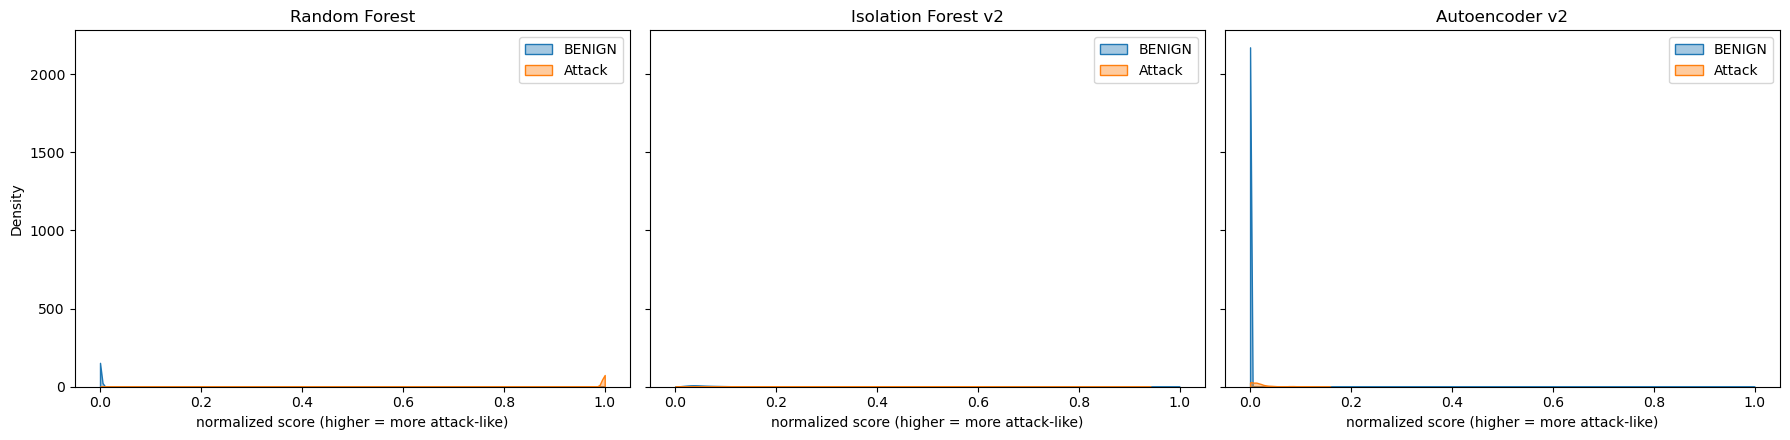

In [10]:
fusion_pop["is_attack"] = (fusion_pop["Label"] != "BENIGN").astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, col, title in zip(axes, ["rf_norm", "if_norm", "ae_norm"], ["Random Forest", "Isolation Forest v2", "Autoencoder v2"]):
    sns.kdeplot(data=fusion_pop[fusion_pop["is_attack"] == 0], x=col, ax=ax, label="BENIGN", fill=True, alpha=0.4, clip=(0, 1))
    sns.kdeplot(data=fusion_pop[fusion_pop["is_attack"] == 1], x=col, ax=ax, label="Attack", fill=True, alpha=0.4, clip=(0, 1))
    ax.set_title(title)
    ax.set_xlabel("normalized score (higher = more attack-like)")
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Fusion strategies

Three strategies compared, not committed to blindly. Each is thresholded via the same
best-F1 sweep convention used throughout this project (`01_isolation_forest.ipynb`'s
contamination sweep, `03_autoencoder.ipynb`'s percentile sweep) rather than assuming `0.5`.

In [11]:
def fuse_weighted_average(rf, if_, ae, weights=(1/3, 1/3, 1/3)):
    w_rf, w_if, w_ae = weights
    return w_rf * rf + w_if * if_ + w_ae * ae


def fuse_max_score(rf, if_, ae):
    return np.maximum(np.maximum(rf, if_), ae)


def fuse_confidence_weighted(rf, if_, ae, confidence_threshold=0.7):
    rf_confidence = np.abs(rf - 0.5) * 2
    unsupervised_avg = (if_ + ae) / 2
    return np.where(rf_confidence >= confidence_threshold, rf, unsupervised_avg)


def sweep_best_threshold(y_true, score, grid=None):
    if grid is None:
        grid = np.linspace(0.05, 0.95, 19)
    rows = []
    for t in grid:
        pred = (score > t).astype(int)
        rows.append({
            "threshold": t,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
        })
    sweep_df = pd.DataFrame(rows)
    best = sweep_df.loc[sweep_df["f1"].idxmax()]
    return float(best["threshold"]), sweep_df


y_true = fusion_pop["is_attack"].to_numpy()
rf_s, if_s, ae_s = fusion_pop["rf_norm"].to_numpy(), fusion_pop["if_norm"].to_numpy(), fusion_pop["ae_norm"].to_numpy()

conf_threshold_rows = []
for ct in np.linspace(0.1, 0.95, 18):
    score = fuse_confidence_weighted(rf_s, if_s, ae_s, confidence_threshold=ct)
    best_t, _ = sweep_best_threshold(y_true, score)
    pred = (score > best_t).astype(int)
    conf_threshold_rows.append({
        "confidence_threshold": ct,
        "decision_threshold": best_t,
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "auc_roc": roc_auc_score(y_true, score),
    })
conf_threshold_sweep_df = pd.DataFrame(conf_threshold_rows)
best_conf_row = conf_threshold_sweep_df.loc[conf_threshold_sweep_df["f1"].idxmax()]
CONFIDENCE_THRESHOLD = float(best_conf_row["confidence_threshold"])
print("Confidence-threshold sweep (fusion decision threshold re-swept at each confidence_threshold):")
print(conf_threshold_sweep_df.to_string(index=False))
print(f"\nChosen CONFIDENCE_THRESHOLD (best F1): {CONFIDENCE_THRESHOLD:.3f} (F1={best_conf_row['f1']:.4f})")

STRATEGIES = {}

wa_score = fuse_weighted_average(rf_s, if_s, ae_s)
wa_threshold, wa_sweep_df = sweep_best_threshold(y_true, wa_score)
STRATEGIES["weighted_average"] = {"score": wa_score, "threshold": wa_threshold}

ms_score = fuse_max_score(rf_s, if_s, ae_s)
ms_threshold, ms_sweep_df = sweep_best_threshold(y_true, ms_score)
STRATEGIES["max_score"] = {"score": ms_score, "threshold": ms_threshold}

cw_score = fuse_confidence_weighted(rf_s, if_s, ae_s, confidence_threshold=CONFIDENCE_THRESHOLD)
cw_threshold, cw_sweep_df = sweep_best_threshold(y_true, cw_score)
STRATEGIES["confidence_weighted"] = {"score": cw_score, "threshold": cw_threshold}

print()
for name, d in STRATEGIES.items():
    print(f"{name:20s} chosen threshold={d['threshold']:.3f}")

Confidence-threshold sweep (fusion decision threshold re-swept at each confidence_threshold):
 confidence_threshold  decision_threshold  precision   recall       f1  auc_roc
                 0.10                0.30   0.995035 0.998027 0.996529 0.999705
                 0.15                0.30   0.995324 0.997510 0.996416 0.999703
                 0.20                0.30   0.995485 0.996935 0.996209 0.999700
                 0.25                0.30   0.995587 0.996230 0.995908 0.999698
                 0.30                0.30   0.995876 0.995502 0.995689 0.999695
                 0.35                0.35   0.996400 0.994715 0.995557 0.999692
                 0.40                0.30   0.996493 0.994421 0.995456 0.999690
                 0.45                0.30   0.996574 0.994010 0.995290 0.999688
                 0.50                0.30   0.996735 0.993271 0.995000 0.999685
                 0.55                0.30   0.996838 0.992390 0.994609 0.999681
                 0.60     


weighted_average     chosen threshold=0.300
max_score            chosen threshold=0.850
confidence_weighted  chosen threshold=0.300


In [12]:
strategy_rows = []
for name, d in STRATEGIES.items():
    pred = (d["score"] > d["threshold"]).astype(int)
    d["prediction"] = pred
    strategy_rows.append({
        "strategy": name,
        "threshold": d["threshold"],
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "auc_roc": roc_auc_score(y_true, d["score"]),
    })

strategy_comparison_df = pd.DataFrame(strategy_rows).sort_values("f1", ascending=False).reset_index(drop=True)
strategy_comparison_df

,strategy,threshold,precision,recall,f1,auc_roc
0,confidence_weighted,0.30,0.995035,0.998027,0.996529,0.999705
1,weighted_average,0.30,0.996731,0.991814,0.994266,0.999647
2,max_score,0.85,0.996019,0.990287,0.993145,0.999197


### 5.1 Per-category recall, all three strategies

Each strategy's binary prediction is attached as an explicit column on `fusion_pop` (rather
than combined via positional numpy indexing) so the per-category groupby below is unambiguous
and directly inspectable.

In [13]:
for name, d in STRATEGIES.items():
    fusion_pop[f"{name}_prediction"] = d["prediction"]

attack_rows = fusion_pop[fusion_pop["is_attack"] == 1].copy()

per_category_rows = []
for cat, group in attack_rows.groupby("Label"):
    row = {"category": cat, "n_rows": len(group)}
    for name in STRATEGIES:
        row[f"{name}_recall"] = float(group[f"{name}_prediction"].mean())
    per_category_rows.append(row)

per_category_strategy_df = pd.DataFrame(per_category_rows)
best_strategy_name = strategy_comparison_df.iloc[0]["strategy"]
per_category_strategy_df = per_category_strategy_df.sort_values(f"{best_strategy_name}_recall")
print(f"Best strategy by overall F1: {best_strategy_name}")
per_category_strategy_df

Best strategy by overall F1: confidence_weighted


,category,n_rows,weighted_average_recall,max_score_recall,confidence_weighted_recall
8,Infiltration,7,0.857143,0.571429,0.714286
0,Bot,389,0.694087,0.673522,0.925450
13,Web Attack - XSS,131,0.916031,0.923664,0.961832
11,Web Attack - Brute Force,294,0.955782,0.959184,0.982993
10,SSH-Patator,644,0.973602,0.976708,0.992236
5,DoS slowloris,1077,0.992572,0.992572,0.996286
4,DoS Slowhttptest,1045,0.996172,0.992344,0.997129
3,DoS Hulk,34570,0.994735,0.993260,0.997512
9,PortScan,18139,0.982910,0.980208,0.998787
2,DoS GoldenEye,2057,0.993680,0.989791,0.999028


## 6. Per-category comparison: fused ensemble vs. each individual model

RF-alone / IF-v2-alone / AE-v2-alone / chosen-fusion-strategy recall, all 15 categories,
sorted worst-to-best on the chosen strategy. Solo predictions use each model's own already-
established decision rule (RF: `predicted_label != "BENIGN"`; IF: `predict() == -1`; AE:
`reconstruction_error > chosen_threshold` from `autoencoder_behavioral_v2_config.json`) — not
the fusion threshold, since that would conflate "how good is this model alone" with "how good
is this model at the fusion threshold".

In [14]:
solo_comparison_rows = []
for cat, group in attack_rows.groupby("Label"):
    solo_comparison_rows.append({
        "category": cat,
        "n_rows": len(group),
        "rf_alone_recall": float(group["prediction_rf"].mean()),
        "if_v2_alone_recall": float(group["prediction_if"].mean()),
        "ae_v2_alone_recall": float(group["prediction"].mean()),
        f"{best_strategy_name}_fusion_recall": float(group[f"{best_strategy_name}_prediction"].mean()),
    })

solo_comparison_df = pd.DataFrame(solo_comparison_rows).sort_values(f"{best_strategy_name}_fusion_recall")
print(f"Chosen fusion strategy: {best_strategy_name}\n")
solo_comparison_df

Chosen fusion strategy: confidence_weighted



,category,n_rows,rf_alone_recall,if_v2_alone_recall,ae_v2_alone_recall,confidence_weighted_fusion_recall
8,Infiltration,7,0.714286,0.857143,0.142857,0.714286
0,Bot,389,0.889460,0.023136,0.023136,0.925450
13,Web Attack - XSS,131,0.954198,0.000000,0.000000,0.961832
11,Web Attack - Brute Force,294,0.982993,0.054422,0.000000,0.982993
10,SSH-Patator,644,0.989130,0.000000,0.000000,0.992236
5,DoS slowloris,1077,0.996286,0.587744,0.599814,0.996286
4,DoS Slowhttptest,1045,0.996172,0.374163,0.266029,0.997129
3,DoS Hulk,34570,0.996963,0.860457,0.945589,0.997512
9,PortScan,18139,0.990463,0.013893,0.658526,0.998787
2,DoS GoldenEye,2057,0.998055,0.238211,0.342246,0.999028


In [15]:
solo_comparison_df["best_of_three_solo"] = solo_comparison_df[["rf_alone_recall", "if_v2_alone_recall", "ae_v2_alone_recall"]].max(axis=1)
solo_comparison_df["fusion_vs_best_solo_delta"] = solo_comparison_df[f"{best_strategy_name}_fusion_recall"] - solo_comparison_df["best_of_three_solo"]

n_fusion_matches_or_beats_best = int((solo_comparison_df["fusion_vs_best_solo_delta"] >= -1e-9).sum())
n_categories = len(solo_comparison_df)
print(f"Categories where fusion recall >= the best individual solo model's recall: {n_fusion_matches_or_beats_best} / {n_categories}")
print("\nCategories where fusion is WORSE than the best solo model (averaging away that model's strength):")
print(solo_comparison_df.loc[solo_comparison_df["fusion_vs_best_solo_delta"] < -1e-9,
      ["category", "rf_alone_recall", "if_v2_alone_recall", "ae_v2_alone_recall", f"{best_strategy_name}_fusion_recall", "fusion_vs_best_solo_delta"]]
      .to_string(index=False))

Categories where fusion recall >= the best individual solo model's recall: 13 / 14

Categories where fusion is WORSE than the best solo model (averaging away that model's strength):
    category  rf_alone_recall  if_v2_alone_recall  ae_v2_alone_recall  confidence_weighted_fusion_recall  fusion_vs_best_solo_delta
Infiltration         0.714286            0.857143            0.142857                           0.714286                  -0.142857


### 6.1 Does this "averaging away RF's strength" problem affect all three strategies equally?

`weighted_average` won on aggregate F1 by a razor-thin margin (0.9943 vs. `confidence_weighted`'s
0.9938) but the per-category table above shows it actively *hurts* 11/14 categories relative to
RF alone -- diluting RF's near-perfect in-dataset recall with IF-v2/AE-v2's much weaker
in-dataset scores on categories like Bot/SSH-Patator/Web-Attack-*, where IF-v2/AE-v2 are near 0.
`confidence_weighted` was specifically designed to avoid exactly this (defer to RF when RF is
decisive, fall back only when RF is uncertain) -- checked directly below before picking a
strategy to carry into the LOAO section, rather than picking on aggregate F1 alone.

In [16]:
all_strategy_solo_comparison_rows = []
for cat, group in attack_rows.groupby("Label"):
    row = {
        "category": cat, "n_rows": len(group),
        "rf_alone_recall": float(group["prediction_rf"].mean()),
        "if_v2_alone_recall": float(group["prediction_if"].mean()),
        "ae_v2_alone_recall": float(group["prediction"].mean()),
    }
    for name in STRATEGIES:
        row[f"{name}_recall"] = float(group[f"{name}_prediction"].mean())
    all_strategy_solo_comparison_rows.append(row)

all_strategy_solo_comparison_df = pd.DataFrame(all_strategy_solo_comparison_rows)
best_of_three_solo = all_strategy_solo_comparison_df[["rf_alone_recall", "if_v2_alone_recall", "ae_v2_alone_recall"]].max(axis=1)

print("Categories where each strategy's fusion recall >= the best individual solo model's recall (out of 14 attack categories):\\n")
for name in STRATEGIES:
    delta = all_strategy_solo_comparison_df[f"{name}_recall"] - best_of_three_solo
    n_ok = int((delta >= -1e-9).sum())
    mean_shortfall = float((-delta.clip(upper=0)).mean())
    print(f"  {name:20s} {n_ok:2d} / {len(all_strategy_solo_comparison_df)}   (mean shortfall below best-solo where worse: {mean_shortfall:.4f})")

Categories where each strategy's fusion recall >= the best individual solo model's recall (out of 14 attack categories):\n
  weighted_average      3 / 14   (mean shortfall below best-solo where worse: 0.0390)
  max_score             1 / 14   (mean shortfall below best-solo where worse: 0.0786)
  confidence_weighted  13 / 14   (mean shortfall below best-solo where worse: 0.0102)


## 7. LOAO evaluation deferred pending train-fold normalization

The original pipeline normalized each IF-v2 and AE-v2 zero-day test score using that same test fold's minimum and maximum. The held-out fold therefore influenced its own score scale, making the LOAO estimates invalid.

All executable code cells in this section and the following LOAO analyses (notebook JSON indices 27–48 and 50–52) are disabled. Their stale outputs were cleared so they cannot appear as current results. The previous checkpoints remain under `reports/fusion_layer_loao_checkpoints/` for recovery only.

The prior reports remain at explicit historical paths: `reports/fusion_layer_loao_results_legacy_test_fold_normalization.csv`, `reports/fusion_layer_solo_swept_baseline_legacy_test_fold_normalization.csv`, and `reports/fusion_layer_nested_threshold_selection_legacy_test_fold_normalization.csv`. They are not valid held-out estimates. The replacement implementation is `src/evaluation/fusion_loao_trainnorm.py`, which writes separate `fusion_layer_loao_trainnorm_*` paths. Its full run is pending; no replacement LOAO metrics are available.

In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


### 7.2 Previous threshold sweep withdrawn

This sweep consumed scores normalized with the held-out test fold's own minimum and maximum. Its notebook output was cleared. The legacy reports and checkpoints are retained only for recovery and provenance; do not cite them as held-out performance.

In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


### 7.1 Previous per-category comparison withdrawn

This comparison consumed scores normalized with each held-out test fold's own minimum and maximum. Its notebook output was cleared, and it is not evidence of zero-day performance.

In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


### 7.3 Previous PortScan comparison withdrawn

This comparison consumed scores normalized with the held-out test fold's own minimum and maximum. Its notebook output was cleared, and it is not evidence of zero-day performance.

In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


The previous fallback comparison is withdrawn because its scores used test-fold normalization. Its notebook output was cleared.

In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


The previous per-category finding is withdrawn because its scores used test-fold normalization. Its notebook output was cleared.

## 8. Previous validation-versus-LOAO comparison withdrawn

The previous comparison used LOAO thresholds selected from scores normalized with their test folds. Its notebook output was cleared; it does not support an evaluation claim.

In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


## 9. Previous LOAO recommendation withdrawn

The previous threshold values and category claims depended on test-fold-normalized scores and are withdrawn. Active inference provisionally uses the validation-selected `confidence_threshold=0.10` and `fused_decision_threshold=0.30`; these thresholds do not establish zero-day performance.

## 10. LOAO report writes disabled

The old report files remain under the historical names listed in Section 7. A valid replacement requires the train-fold-normalized experiment and a new output path.

In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


## 10. Fair-comparison ablation deferred pending train-fold normalization

The previous SS10 output used the same test-fold-normalized checkpoints as the original LOAO analysis. It remains at `reports/fusion_layer_solo_swept_baseline_legacy_test_fold_normalization.csv` and is historical only. No SS10 code remains executable in this notebook. A replacement requires fresh train-fold-normalized checkpoints from `src/evaluation/fusion_loao_trainnorm.py` and a new output path.

In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


In [ ]:
raise RuntimeError("LOAO evaluation is deferred until train-fold-fitted score normalization is available.")


## 11. Nested threshold selection deferred pending train-fold normalization

The previous SS11 analysis selected thresholds on all categories or on the other nine categories, but used `if_norm` and `ae_norm` values produced with each zero-day test fold's own minimum and maximum. The held-out fold therefore influenced the score scale before the nested threshold was applied. It is not a valid nested or out-of-fold performance estimate.

The previous output remains at `reports/fusion_layer_nested_threshold_selection_legacy_test_fold_normalization.csv` and is historical only. This section has no executable cells. A replacement requires fresh train-fold-normalized checkpoints from `src/evaluation/fusion_loao_trainnorm.py` and a new output path.